# Снижение активности по картам: кто, насколько и за счёт чего

**Автор:** Мищенко Мария
**Период данных:** 2024-01-01 — 2025-06-30
**Подготовлено для:** департамент розничных продуктов, банк «Меридиан»

<!--
Этот ноутбук собирается в HTML командой:
jupyter nbconvert --to html --no-input --execute 02_report.ipynb --output report.html

Поэтому: кода читатель не видит, все графики и таблицы получены
исполнением, числа в тексте должны совпадать с выводом кода.
Лимит: 6 страниц и 8 графиков.
-->

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

clean = pd.read_parquet("clean_data.parquet")

## 1. Главное

<!-- 3–5 выводов с числами. Пишется последним, читается первым.
     Каждый вывод — утверждение, а не тема. Не «анализ активности»,
     а «активность упала на X% у группы Y за счёт Z». -->

1. Активность клиентов снизилась, при чём основной вклад в общее сокращение успешных карточных транзакций внесли клиенты с сильным снижением активности(более чем на 70%): на них приходится около 74% общего падения. 
2. Снижение затронуло все основные категории расходов, при этом процентные значения падений находятся примерно в одном диапазоне. Наибольший абсолютный вклад вносит категория "Продукты"(~26.5%, 31% и 27.1% по выделенным группами соответственно), т.к. она в целом наиболее частая в категории трат. Если же смотреть по проценту падения метрики по каждой категории, то для каждой из групп больше всего снижаются траты на одежду и обувь: (G1: 87.2%, 69.4%, 83.1%), а вторые по величине падения активности: для G1 и G3 - Развлечения и досуг(86.8%, 82.8%), для G2 - Продукты(69.3%)  
3. Выделены три основные группы клиентов, давших согласие на маркетинговую коммуникацию, что делает возможным повышение их активности: 
Суммарная численность клиентов - 884 клиента.
4. Причины снижения активности в группах:
- G1: у 57.3% процента клиентов наблюдается снижение карточной активности, в то время как число транзакций с другим каналом оплаты повышается, что может говорить о том, что метрика активности у этой группы клиентов снизилась в результате перехода на другие способы оплаты.
- G2: н 98.5% клиентов наблюдается снижение активности как по карточным транзакциям, так и по произведённым другими способами оплаты, что говорит о том, что у этой категории клиентов причина падения метрика не в этом
- G3: y 42.7% клиентов снижение карточной активности, в то время как число транзакций с другим каналом оплаты повышается, а у оставшихся активность снижается по всем каналам, что также может говорить о том, что причина снижении метрики в совокупности нескольких факторов

## 2. Контекст

<!-- Какое решение поддерживает этот отчёт, 3–5 предложений. -->
За последние полгода банк видит, что клиенты стали реже пользоваться картами. Департамент планирует кампанию по возврату активности и просит понять, к кому с ней идти. Основная задача - определить метрику активности клиентов, выяснить у кого за счёт чего активность упала и выделить 3-5 групп с понятным правилом "кто - что с ним произошло". Также для каждой группы необходимо понимать, за счёт чего упала активность.

## 3. Данные и ограничения

<!-- Период, число клиентов и операций, что и почему исключено из расчёта,
     чего в данных нет.

     Здесь же одним абзацем: какую метрику активности вы выбрали,
     как она считается и какое снижение она не увидит. -->

- Период: данные охватывают период с 01.01.2024 по 30.06.2025. Из них базовый период - это 2024 год, а оцениваемый - период с января по июнь 2025 года.
- Объём: изначально 5715 строк и 16 столбцов в таблице клиентов, 616993 строк и 9 столбцов в таблице транзакций, после проведения операций фильтрации на этапе preprocessing в таблице клиентов стало 5660 строк и 18 столбцов, а в таблице транзакций - 585067 строк и 11 столбцв. 
- Исключено на этапе preprocessing:
    1. Полные дубликаты строк: 40 из таблицы клиентов и 1283 из таблицы транзакций
    2. Повторяющиеся строки транзакций с совпадением по всем колонкам, но различной записью одной и той же даты в `txn_datetime`. Был оставлен только 1 экземпляр каждого такого дубля
    3. Записи об одном и том же клиенте с совпадением по всем признакам, кроме города/сегмента. По выбранному принципу был оставлен один экземпляр таких дублей
    4. Транзакции с датами, выходящими за указанный в условии период
    5. Невалидные транзакции: дата транзакции более ранняя, чем дата открытия карты

- Исключено(не учитывалось) на этапе выбора метрики и разбиения клиентов по группам:
    1. Транзакции от несуществующих клиентов - тех, что отсутствуют в таблице `clients`
    2. Клиенты, изначально совершавшие маленькое количество транзакций(<6)
    3. Возвраты и отклонённые транзакции
    4. Клиенты, дата регистрации карты которых была позже, чем 01.01.2024

- Нет в данных:
    1. Полных данных об удовлетворённости клиентов: 60% значений в столбце `satisfaction_score` отсутствуют, поэтому этот показатель неинформативенн при разделении клентов на группы.
    2. Информации и транзакицях, оплаченных наличными, поэтому невозможно оценить, компенсировали ли клиенты снижение карточных платежей переходом на наличные.

- Выбранная метрика:
В качестве метрики активности выбираю количество успешных транзакций, совершённых клиентом с типом оплаты "карта", т.к. нас интересует именно факт того, почему стали меньше пользоваться картами. Считаем среднее за месяц в периоде январь-июнь за 2025 и за 2024 года. Умеренным снижением считаем падение не менее, чем на 45%. Порог выбран по 5-му перцентилю колебаний клиентов между первым и вторым полугодиями за 2024 год. Такие вычисления проводились, чтобы оценить изменение метрики в "спокойное" время(базовый период), когда резкого снижения активности не наблюдается, чтобы позже на оцениваемом периоде ошибочно не принять нормальное измнение метрики за снижение активности. Сильным считаем снижение более, чем на 70%. Метрика не увидит снижение среднего чека транзакций при том же их количестве.

## 4. Находки

<!-- По одной находке на подраздел. Заголовок подраздела — вывод,
     а не тема. Под заголовком: график или таблица, затем 2–4
     предложения. -->

### 4.1. Сильная правая асимметрия у графиков распределения величин `monthly_income`

*т.к. таблица clean содержит не всех клиентов, а только отобранных во время анализа, значения квантилей могут несного отличаться от тех, что на графиках в рабочем ноутбуке*

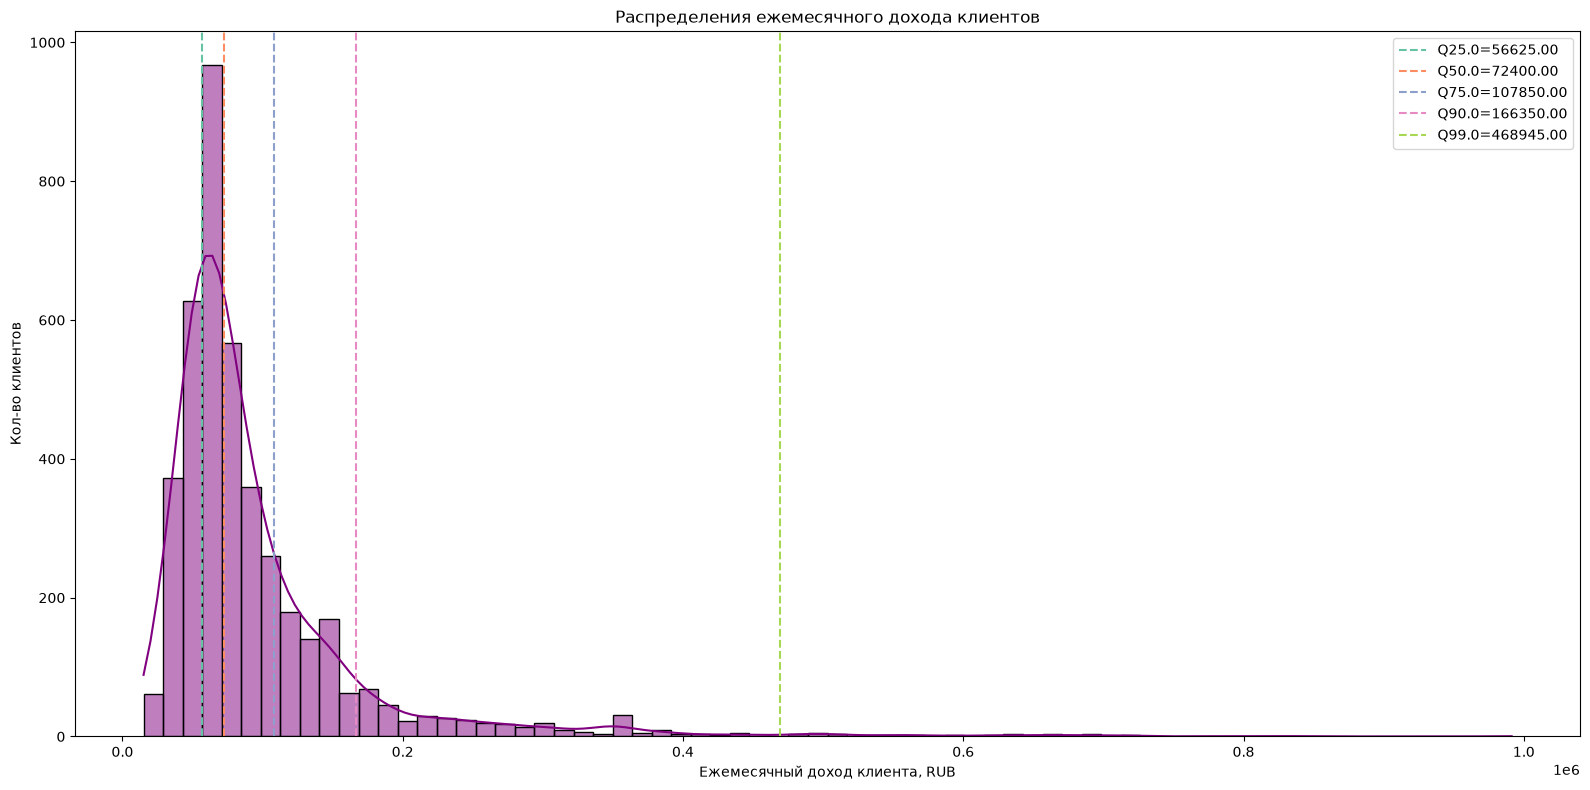

In [2]:
COLS = ["monthly_income"]
fig, ax = plt.subplots(figsize=(16, 8))
quantiles = clean["monthly_income"].quantile([0.25, 0.5, 0.75, 0.9, 0.99])
palette = sns.color_palette('Set2', n_colors=len(quantiles))
sns.histplot(
    clean["monthly_income"], bins=70, kde=True, 
    ax=ax, color="purple"
)
for (q, value), color in zip(quantiles.items(), palette):
    ax.axvline(
        value, 
        linestyle="--",
        label = f"Q{q*100}={value:.2f}",
        color=color
    )
plt.title(f"Распределения ежемесячного дохода клиентов")
plt.xlabel("Ежемесячный доход клиента, RUB")
plt.ylabel("Кол-во клиентов")
plt.legend()

plt.tight_layout()
plt.show()

### 4.2. Средняя активность клиентов существенно заметно в первое полугодие 2025 года по сравнению с первым полугодием 2024

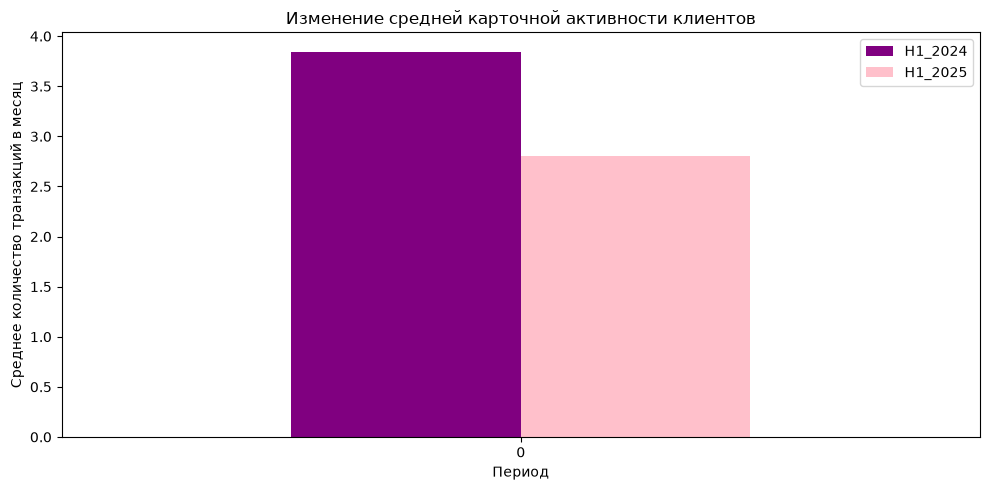

In [3]:
activity_comparison = pd.DataFrame({
    "H1_2024": [clean["avg24"].mean()],
    "H1_2025": [clean["avg25"].mean()]
})

activity_comparison.plot(kind="bar",figsize=(10, 5), color=["purple", "pink"])
plt.ylabel("Среднее количество транзакций в месяц")
plt.xlabel("Период")
plt.title("Изменение средней карточной активности клиентов")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Визуальная оценка общего масштаба снижения

### 4.3. Для выделенных групп характерна разная величина снижения

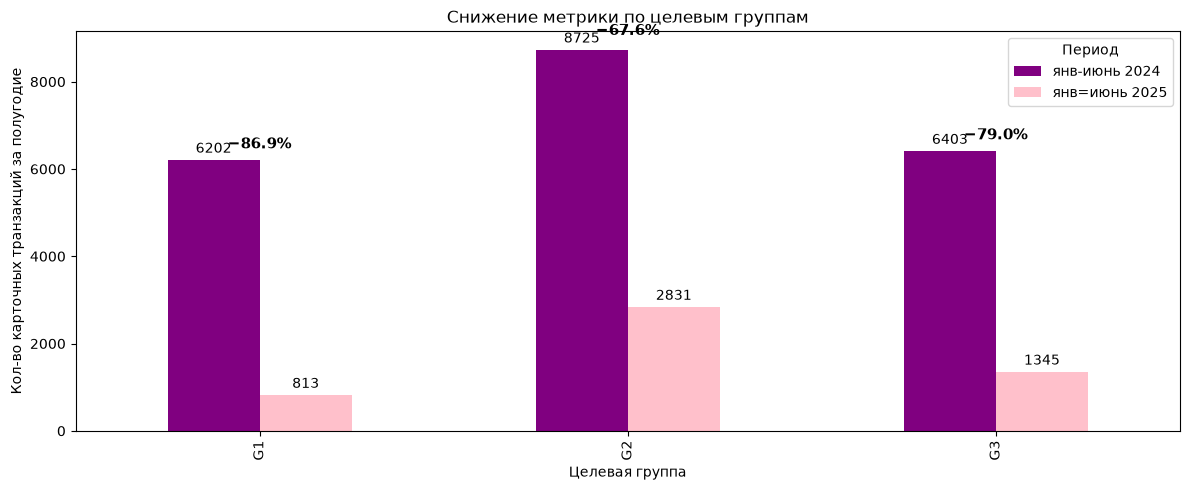

In [14]:
group_activity = (
    clean[clean["final_group"].notna()].groupby("final_group")
    .agg(
        clients=("client_id", "nunique"),
        transactions_2024=("n24", "sum"),
        transactions_2025=("n25", "sum")
    )
)
group_activity["decline_pct"] = ((1 - group_activity["transactions_2025"] / group_activity["transactions_2024"]) * 100).round(1)
ax = group_activity[["transactions_2024", "transactions_2025"]].plot(kind="bar",figsize=(12, 5), color=["purple", "pink"])

# Подписи над столбцами
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)
for i, (_, row) in enumerate(group_activity.iterrows()):
    ax.text(
        i,
        row["transactions_2024"] * 1.03,
        f'−{row["decline_pct"]:.1f}%',
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.xlabel("Целевая группа")
plt.ylabel("Кол-во карточных транзакций за полугодие")
plt.title("Снижение метрики по целевым группам")
plt.legend(["янв-июнь 2024", "янв=июнь 2025"], title="Период")
plt.tight_layout()
plt.show()

Самое сильное снижение активности наблюдается в группе G1: 86.9%

## 5. Группы для кампании

<!-- Таблица: группа, правило отбора, размер, причина падения.
     Ниже — по абзацу на группу. -->


**1. G1**
- Признак:клиенты возрастного диапазона 31-45 лет с установленным приложением, у которых наблюдается резкое и сильное снижение активности
- Кол-во клиентов: 225
- Падение активности в процентах: 86.9%
- Возмодные причины падения: переход клиентов с карточного способа оплаты на какой-то лругой

**2. G2**
- Признак: клиенты массового сегмента без приложения, у которых наблюдается умеренное снижение активности и её затухание к концу исследуемого периода
- Кол-вл клиентов: 406
- Падение активности в процентах: 67.6%
- Возможные причины падения: общее сокращения числа транзакций, сокращение покупок по всем категориям

**3. G3**
- Признак: клиенты из Москвы с приложением, сильное снижение к концу периода
- Кол-во клиентов: 253
- Падения активности в процентах: 79.0%
- Возможные причины падения: частичное замещение карточных транзакций на другие способы оплаты

## 6. Кого не включаем и почему

<!-- Отдельным списком. Для каждой категории: кто это, сколько их,
     почему кампания им не нужна или бесполезна. -->

1. Клиентов, которые не согласны на маркетинговую коммуникацию. Для таких клиентов невозможно будет предпринять какие-либо шаги для возвращения им активности. 
2. Клиентов с низким количеством транзакций на базовом периоде(<6 транзакций). Даже небольшое численное снижение активности у таких клиентов приведёт к значительному процентному снижению, что может исказить результаты.
3. Клиентов возрастной группы 18-31. Численность группы оказалась слишком маленькой для формирования отдельной группы на основе такого признака. Не подходит по изначальному ограничению на минимальное кол-во клиентов в группе.
4. Клиенты без выраженного снижения активности, т.к. они не соответствуют изначальной цели компании - возвращению клиентов, снизивших свою активность.

## 7. Что проверили и что не подтвердилось

<!-- 3–5 строк, по одной на гипотезу, каждая с числом. -->
1. Отрицательные значения в столбце `monthly_amount` являются выбросами и скорее всего будут удалены. Не подтвердилось: по смыслу это скорее специальный код для обозначения недоступности месячного дохода клиента. Он был заменён на прорпуск(NaN), которые впоследствии были обработаны.
2. Падение активности в основном вызвано оттоком клиентов, т.е. полным их уходом - не подтвердилось. Основной вклад в общее сокращение успешных карточных транзакций внесли клиенты с сильным снижением активности(более чем на 70%): на них приходится около 74% общего падения. 
3. Возрастная группа `18-31` - признак для отбора в группы.
Не подтвердилась, т.к. хоть снижение активности в этой группе и показательное, её размер слишком маленький, и не удовлетворяет условию, что группы должна состоять минимум из 150 человек.

## 8. Приложение

### 8.1. Сводка журнала изменений

<!-- 5–10 строк по типам нарушений: поле, что найдено, сколько строк,
     что сделано. Полный журнал — в cleaning_log.csv. -->

In [15]:
cleaning_log = pd.read_csv("cleaning_log.csv")
cleaning_log.head(3)

,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,birth_date,неподходящий тип данных,все строки,5715.0,1937-05-31,изменён тип данных с str на datetime64 с помощ...,1937-05-31,"необходимо для корректной работы с датами, выд..."
1,registration_date,неподходящий тип данных,все строки,5715.0,31.01.2025,изменён тип данных с str на datetime64 с помощ...,31-01-2025,"необходимо для корректной работы с датами, выд..."
2,card_open_date,неподходящий тип данных,все строки,5715.0,26.08.2019,изменён тип данных с str на datetime64 с помощ...,2019-08-26,"необходимо для корректной работы с датами, выд..."


### 8.2. Методика

<!-- Точные формулы, фильтры, пороги и их значения. Всё, что нужно,
     чтобы повторить расчёт. -->
1. Подготовка данных
В анализ включались успешные карточные транзакции с положительной суммой (channel == "Карта", status == "успешно", amount > 0). В выборку вошли клиенты, совершившие не менее 6 карточных транзакций в первом полугодии 2024 года.
2. Расчёт активности 
Выбранная метрика - количество успешных транзакций, совершённых клиентом с типом оплаты "карта".
3. Классификаци снижения активности:
Задаём два порога:
- умеренное снижение активность (порог для разницы активностей за первое полугодие 2024 и 2025 годов: -0.45)
- сильное снижение активности (порог для разницы активностей за первое полугодие 2024 и 2025 годов: -0.7)
И разделим активных в рассматриваемый период времени клиентов на группы по характеру изменения активности:
- перестал пользоваться картой вообще: метрика = 0 за полугодие 2025 года
- клиент с редкими покупками: малое транзакций за рассматриваемое полугодие 2024 года
- клиент с умеренным снижением: посчитанная разница между `n25` и `n24` <= -0.45
- клиент с умеренным снижением: посчитанная разница между `n25` и `n24` <= -0.7
- стабильный клиент: посчитанная разница между `n25` и `n24` <= 0.3
4. Анализ траекторий за оцениваемый период
сравнивалось кол-во транзакций в первом и втором кварталах 2025 года
- оба значения равно 0 => нет покупок
- активность снизилась не менее, чем в 2 раза => затухание к концу периода
- восстановление - активность выросла не менее, чем в 1.5 раза
- остальные случаи - стабильно низкий уровень
5. Формирование групп 
Сделана статистика по характеру активности для признаков клиента, по итогу чего выделены 3 основные группы:
- G1: Клиенты возрастной категории 31-45 с мобильным приложением
- G2: Клиенты массового сегмента без мобильного приложения
- G3: Клиенты из Москвы с мобильным приложением

Группы G1 и G3 пересекаются, как уже уточнялось ранее, поэтому всех клиентов на персечении оставляем в группе G3, чтобы там были все клиенты из Москвы с приложением. Таким образом, каждый клиент мог попасть только в одну целевую группу. Итоговая выборка включила 884 клиента. При формировании групп учитывались ограничения заказчика: от 150 до 2000 уникальных клиентов суммарно.

### 8.3. Использование ИИ

<!-- 3–5 строк: для чего использовали и что проверили сами. -->
Использовала ИИ для помощи в работы с датами и правильного выделения временных отрезков. Также использовала для уточнения более оптимального выбора способа исследования зависимостей(например, когда строила некоторые статистики по признакам клиентов для определения групп).